In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

df = pd.read_csv("rapido_july2025_data.csv")
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Booking_ID                  30000 non-null  object 
 1   Booking_Status              30000 non-null  object 
 2   Booking_Value               30000 non-null  float64
 3   Customer_ID                 30000 non-null  object 
 4   Driver_ID                   30000 non-null  object 
 5   Pickup_Location             30000 non-null  object 
 6   Drop_Location               30000 non-null  object 
 7   Ride_Distance(km)           30000 non-null  float64
 8   Ride_Time(min)              30000 non-null  int64  
 9   Date                        30000 non-null  object 
 10  Time                        30000 non-null  object 
 11  Vehicle_Type                30000 non-null  object 
 12  Vehicle_Image               30000 non-null  object 
 13  Payment_Method              300

In [ ]:
# Drop non-predictive identifiers and data leaks
cols_to_drop = ['Booking_ID', 'Customer_ID', 'Driver_ID', 'Pickup_Location', 'Drop_Location', 'Date', 'Time', 'Vehicle_Image', 'Incomplete_Rides_Reason', 'Canceled_Rides_by_Customer', 'Canceled_Rides_by_Driver', 'Incomplete_Rides', 'Total_Bookings', 'Canceled_Bookings', 'Canceled_Percentage', 'V_TAT', 'C_TAT']
df = df.drop(columns=cols_to_drop, errors='ignore')

# Select Features (X) and Target (y)
X = pd.get_dummies(df.drop('Booking_Status', axis=1)) # Convert text categories to numeric
y = df['Booking_Status']

# Normalize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Split Data (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

In [ ]:
# Using Decision Tree Classifier with Gini
dt_model = DecisionTreeClassifier(criterion="gini", max_depth=5, random_state=42)
dt_model.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=5, random_state=42)

Decision Tree Accuracy: 0.8196666666666667

Classification Report:
               precision    recall  f1-score   support

   Cancelled       0.00      0.00      0.00       736
   Completed       0.82      1.00      0.90      4919
  Incomplete       0.00      0.00      0.00       345

    accuracy                           0.82      6000
   macro avg       0.27      0.33      0.30      6000
weighted avg       0.67      0.82      0.74      6000



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


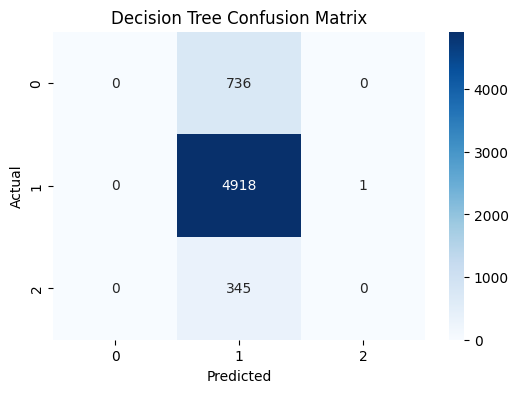

In [ ]:
y_pred_dt = dt_model.predict(X_test)
print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))
print("\nClassification Report:\n", classification_report(y_test, y_pred_dt))

# Confusion Matrix
plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test, y_pred_dt), annot=True, fmt='d', cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")
plt.show()

In [ ]:
def custom_decision_tree(X_train, y_train, X_test):
    # Using 'entropy' instead of 'gini'
    model = DecisionTreeClassifier(criterion="entropy", max_depth=5, random_state=42)
    model.fit(X_train, y_train)
    return model.predict(X_test)

y_pred_custom_dt = custom_decision_tree(X_train, y_train, X_test)
print("Custom DT Accuracy:", accuracy_score(y_test, y_pred_custom_dt))

Custom DT Accuracy: 0.819


In [ ]:
# Train a Naïve Bayes Model
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

GaussianNB()

Naïve Bayes Model Accuracy: 0.8198333333333333


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Classification Report:
               precision    recall  f1-score   support

   Cancelled       0.00      0.00      0.00       736
   Completed       0.82      1.00      0.90      4919
  Incomplete       0.00      0.00      0.00       345

    accuracy                           0.82      6000
   macro avg       0.27      0.33      0.30      6000
weighted avg       0.67      0.82      0.74      6000



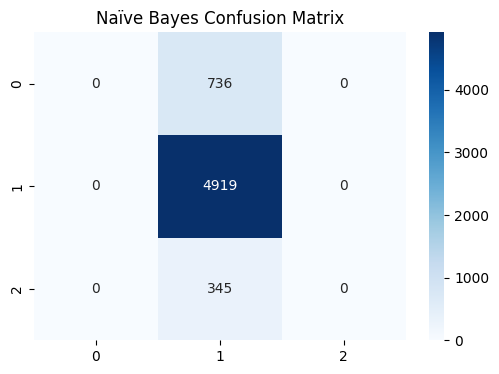

In [ ]:
y_pred_nb = nb_model.predict(X_test)
print("Naïve Bayes Model Accuracy:", accuracy_score(y_test, y_pred_nb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_nb))

plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test, y_pred_nb), annot=True, fmt='d', cmap="Blues")
plt.title("Naïve Bayes Confusion Matrix")
plt.show()

In [ ]:
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)
y_pred_nb = nb_model.predict(X_test)

print("Naïve Bayes Accuracy:", accuracy_score(y_test, y_pred_nb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_nb))

Naïve Bayes Accuracy: 0.8198333333333333

Classification Report:
               precision    recall  f1-score   support

   Cancelled       0.00      0.00      0.00       736
   Completed       0.82      1.00      0.90      4919
  Incomplete       0.00      0.00      0.00       345

    accuracy                           0.82      6000
   macro avg       0.27      0.33      0.30      6000
weighted avg       0.67      0.82      0.74      6000



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
def custom_naive_bayes(X_train, y_train, X_test):
    model = GaussianNB()
    model.fit(X_train, y_train)
    return model.predict(X_test)

y_pred_custom_nb = custom_naive_bayes(X_train, y_train, X_test)
print("Custom NB Accuracy:", accuracy_score(y_test, y_pred_custom_nb))

Custom NB Accuracy: 0.8198333333333333
